Задача: собрать информацию о друзьях и друзьях друзей в VK, построить ненаправленный граф, оценить центральность: по посредничеству, по близости, собственного вектора (получить 3 числа)


Так как с VK возникли проблемы, берем данные с такой же задумкой: анонимизированные пользователи Facebook и связи между ними. Струкутра графа:

Первая колонка = пользователь A

Вторая колонка = пользователь B

In [1]:
import gzip
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
FILE_PATH = "facebook_combined.txt.gz"

In [3]:
G = nx.Graph()

with gzip.open(FILE_PATH, "rt", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line:
            continue

        user1, user2 = map(int, line.split())
        G.add_edge(user1, user2)

In [18]:
print("Количество пользователей (вершин):", G.number_of_nodes())
print("Количество связей (ребер):", G.number_of_edges())

Количество пользователей (вершин): 4039
Количество связей (ребер): 88234


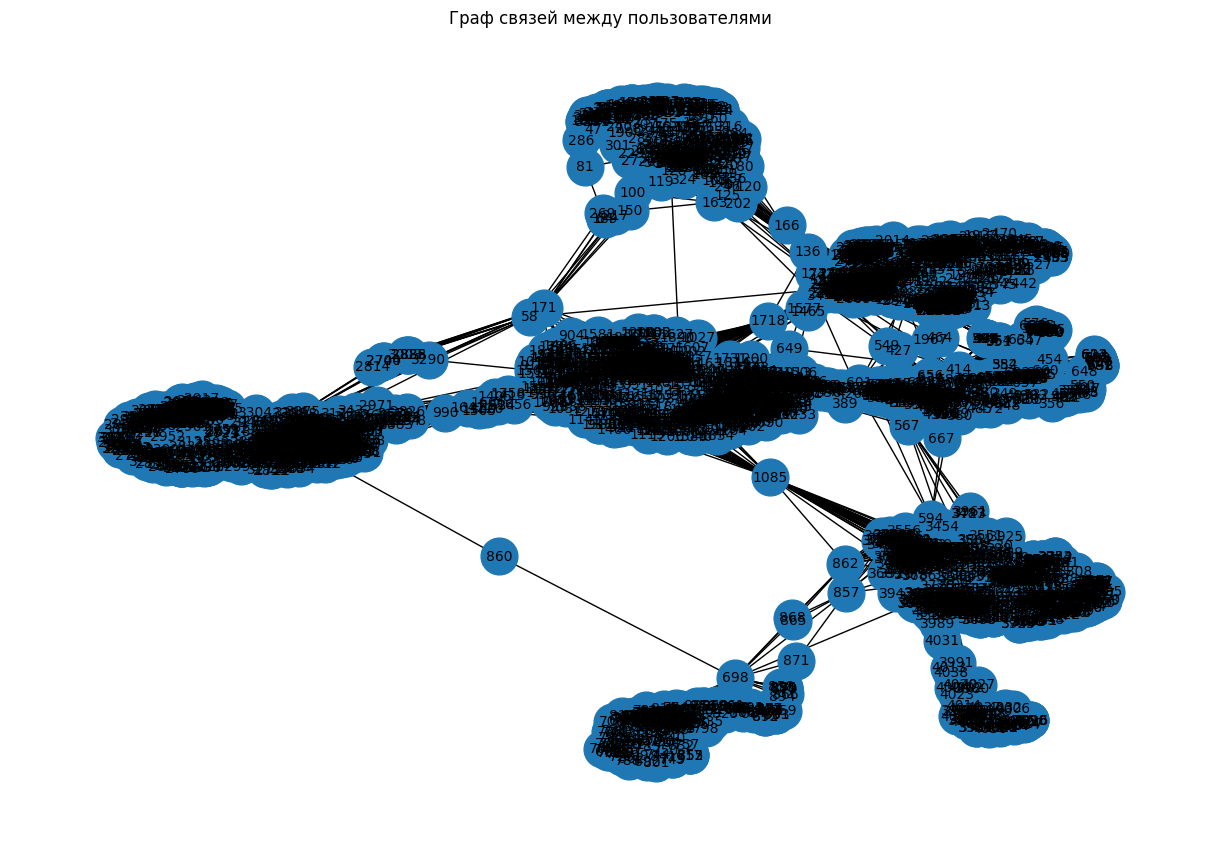

In [5]:
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=700,
    font_size=10
)

plt.title("Граф связей между пользователями")
plt.show()

## Центральность по посредничеству 
показывает, насколько часто пользователь находится на кратчайших путях между другими пользователями
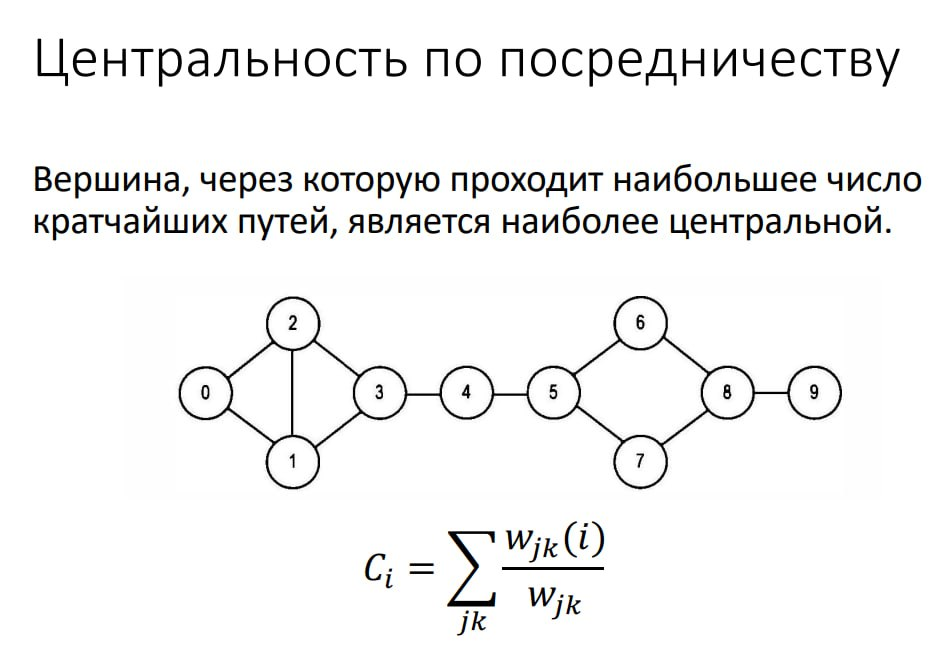

## Центральность по близости 
показывает, насколько быстро пользователь может достичь остальных вершин графа
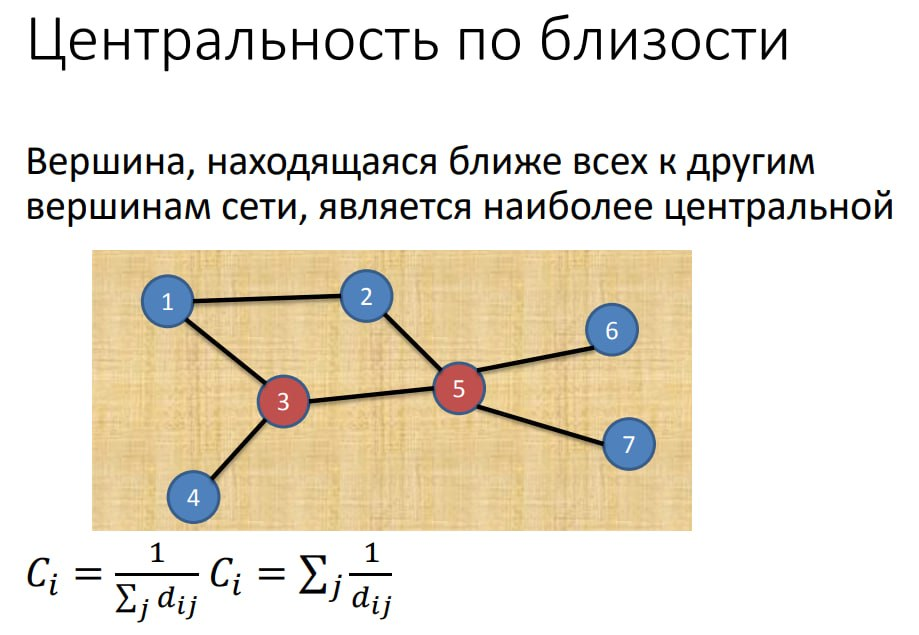

## Собственная векторная центральность 
учитывает не только количество связей, но и с кем именно человек связан
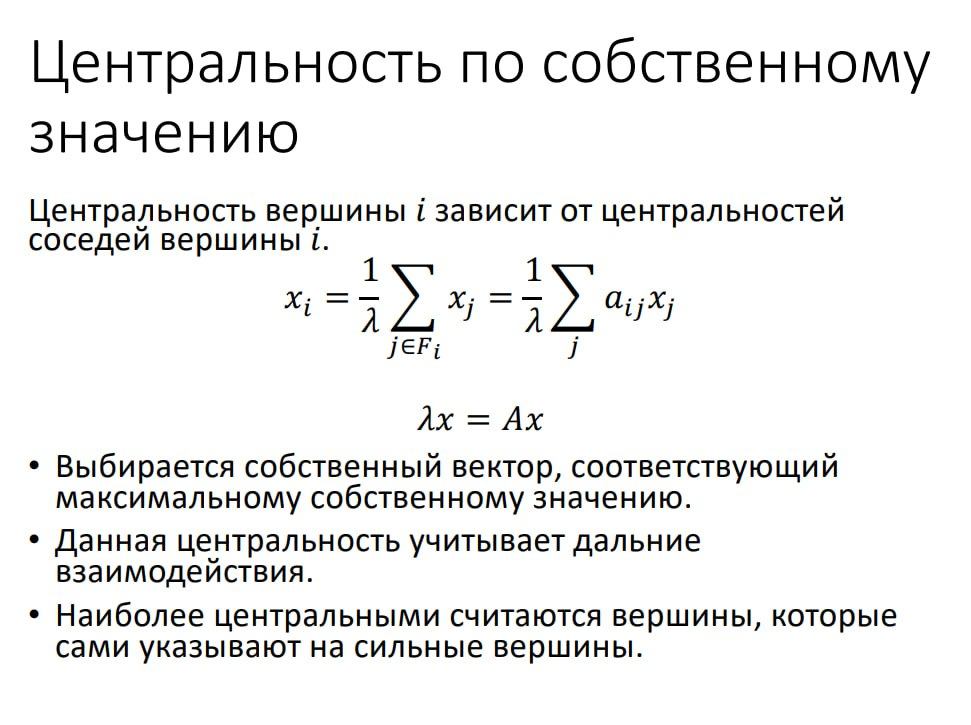

In [6]:
betweenness = nx.betweenness_centrality(G)
closeness = nx.closeness_centrality(G)
eigenvector = nx.eigenvector_centrality(G, max_iter=1000)

In [7]:
# Поиск самых центральных пользователей
most_betweenness = max(betweenness, key=betweenness.get)
most_closeness = max(closeness, key=closeness.get)
most_eigenvector = max(eigenvector, key=eigenvector.get)

print("Самые центральные пользователи")
print("По посредничеству:", most_betweenness, f"({betweenness[most_betweenness]})")
print("По близости:", most_closeness, f"({closeness[most_closeness]})")
print("По собственному вектору:", most_eigenvector, f"({eigenvector[most_eigenvector]})")

Самые центральные пользователи
По посредничеству: 107 (0.4805180785560152)
По близости: 107 (0.45969945355191255)
По собственному вектору: 1912 (0.09540696149067629)


In [17]:
user1 = 107
user2 = 1912

if G.has_edge(user1, user2):
    print(f"Пользователи {user1} и {user2} друзья")
else:
    print(f"Пользователи {user1} и {user2} не являются друзьями")

Пользователи 107 и 1912 не являются друзьями


In [ ]:
# Рассматриваем пользователя, который больше всего похож на нас :)
target_user = 860  
target_betweenness = betweenness[target_user]
target_closeness = closeness[target_user]
target_eigenvector = eigenvector[target_user]

print(f"По посредничеству: {target_betweenness}")
print(f"По близости: {target_closeness}")
print(f"По собственному вектору: {target_eigenvector}")

По посредничеству: 0.05782590687091168
По близости: 0.31492746841366404
По собственному вектору: 4.6012116336824543e-08


Граф вокруг конкретного пользователя

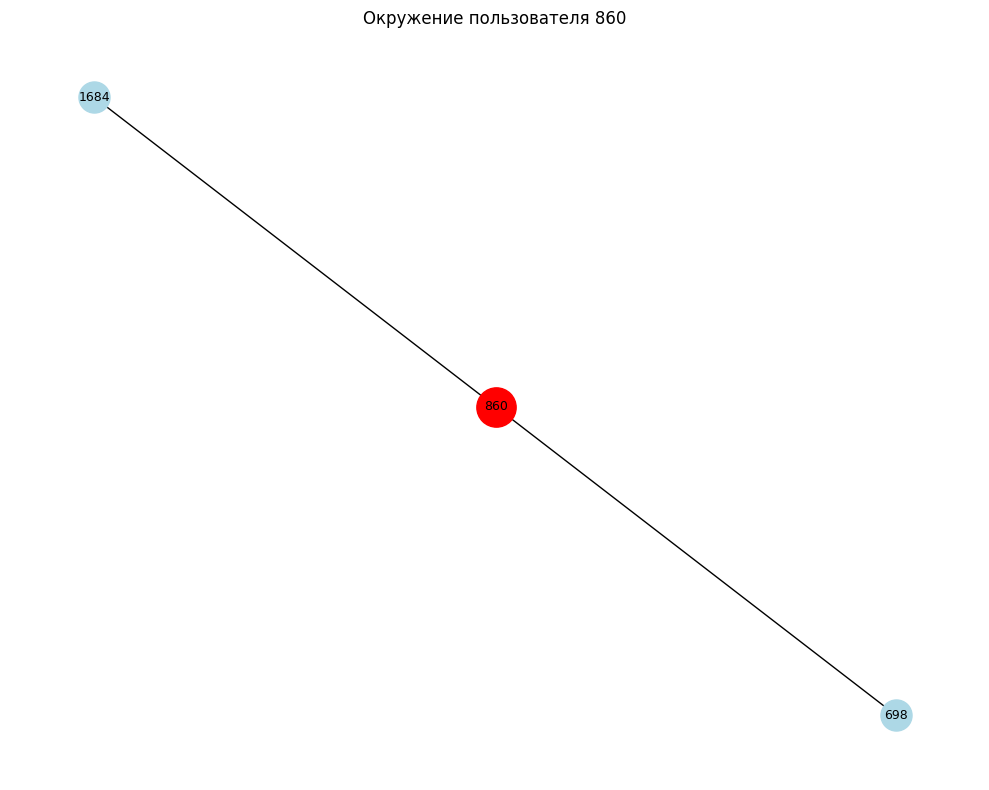

In [ ]:
neighbors = list(G.neighbors(target_user))
nodes_for_subgraph = [target_user] + neighbors
subgraph = G.subgraph(nodes_for_subgraph)

plt.figure(figsize=(10, 8))

pos_sub = nx.spring_layout(subgraph, seed=42)

# Все вершины
nx.draw_networkx_nodes(
    subgraph,
    pos_sub,
    node_size=500,
    node_color="lightblue"
)

# Выбранный пользователь отдельно
nx.draw_networkx_nodes(
    subgraph,
    pos_sub,
    nodelist=[target_user],
    node_size=800,
    node_color="red"
)

# Ребра
nx.draw_networkx_edges(
    subgraph,
    pos_sub,
    width=1
)

# Подписи
nx.draw_networkx_labels(
    subgraph,
    pos_sub,
    font_size=9
)

plt.title(f"Окружение пользователя {target_user}")
plt.axis("off")
plt.tight_layout()
plt.show()